In [16]:
import pandas as pd 
import numpy as np
import torch 
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, Trainer,TrainingArguments
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [2]:
#loading prepared dataset

df = pd.read_csv("final_customer_sentiment_dataset.csv")
df.head()

,text,label
0,Erroneous image Don't be fooled by the carton...,0
1,Not gourmet Not gourmet by any stretch of the ...,0
2,showed more interest in a dust ball my cats lo...,0
3,real candy big pieces? I bought it and I was h...,0
4,Worst of all Timothy's K cups I have tried all...,0


In [3]:
df["label"].value_counts()

label
0    40000
1    40000
2    40000
Name: count, dtype: int64

In [4]:
#Splitting data in train, test & validation

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=42
)

In [5]:
#Convert to HuggingFace Dataset

train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df.reset_index(drop=True))
test_ds  = Dataset.from_pandas(test_df.reset_index(drop=True))

In [6]:
#Loading Tokenizer

tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

In [7]:
#Tokenization 

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=256
    )

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

Map:   0%|          | 0/96000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

In [8]:
#Setting format for pytorch 

columns = ["input_ids", "attention_mask", "label"]

train_ds.set_format(type="torch", columns=columns)
val_ds.set_format(type="torch", columns=columns)
test_ds.set_format(type="torch", columns=columns)

In [9]:
#Load DistilBERT Model

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [10]:
#Classification Metrics 

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted")
    }

In [11]:
#Training Argumrnts 

training_args = TrainingArguments(
    output_dir="./results",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_dir="./logs",
    logging_steps=100,
    report_to="none"
)

#Trainer 
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

/home/mayankk/Deep Learning/torch_env/lib/python3.12/site-packages/transformers/training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [12]:
#Training Model 

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.421200,0.403935,0.835667,0.837122
2,0.298500,0.388440,0.858667,0.859167
3,0.224500,0.437133,0.861417,0.861863


TrainOutput(global_step=18000, training_loss=0.3420324119991726, metrics={'train_runtime': 4809.9752, 'train_samples_per_second': 59.876, 'train_steps_per_second': 3.742, 'total_flos': 1.9075645587456e+16, 'train_loss': 0.3420324119991726, 'epoch': 3.0})

In [13]:
#Evaluation on test set 

test_results = trainer.evaluate(test_ds)
test_results

{'eval_loss': 0.43293407559394836,
 'eval_accuracy': 0.8626666666666667,
 'eval_f1': 0.8630342977483093,
 'eval_runtime': 57.0941,
 'eval_samples_per_second': 210.179,
 'eval_steps_per_second': 13.136,
 'epoch': 3.0}

In [14]:
#Classification report 

preds = trainer.predict(test_ds)
y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Neutral", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86      4000
     Neutral       0.80      0.82      0.81      4000
    Positive       0.93      0.91      0.92      4000

    accuracy                           0.86     12000
   macro avg       0.86      0.86      0.86     12000
weighted avg       0.86      0.86      0.86     12000



In [15]:
trainer.save_model("sentiment_distilbert_best")
tokenizer.save_pretrained("sentiment_distilbert_best")

('sentiment_distilbert_best/tokenizer_config.json',
 'sentiment_distilbert_best/special_tokens_map.json',
 'sentiment_distilbert_best/vocab.txt',
 'sentiment_distilbert_best/added_tokens.json',
 'sentiment_distilbert_best/tokenizer.json')

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

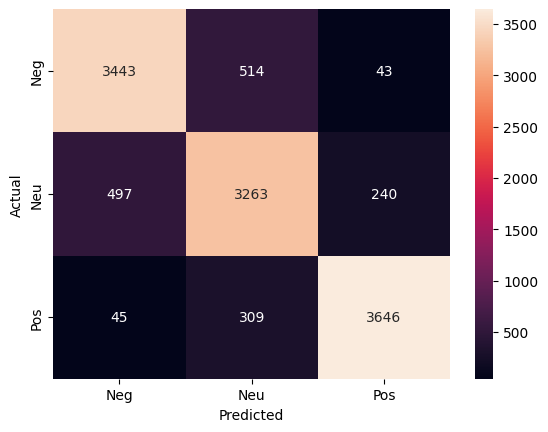

In [18]:
#Confusion metrics

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Neg", "Neu", "Pos"],
    yticklabels=["Neg", "Neu", "Pos"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()